In [1]:
import torch

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [12]:
x = torch.linspace(-2, 2 , 50).unsqueeze(1)

In [13]:
x

tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [14]:
x

tensor([[-2.0000],
        [-1.9184],
        [-1.8367],
        [-1.7551],
        [-1.6735],
        [-1.5918],
        [-1.5102],
        [-1.4286],
        [-1.3469],
        [-1.2653],
        [-1.1837],
        [-1.1020],
        [-1.0204],
        [-0.9388],
        [-0.8571],
        [-0.7755],
        [-0.6939],
        [-0.6122],
        [-0.5306],
        [-0.4490],
        [-0.3673],
        [-0.2857],
        [-0.2041],
        [-0.1224],
        [-0.0408],
        [ 0.0408],
        [ 0.1224],
        [ 0.2041],
        [ 0.2857],
        [ 0.3673],
        [ 0.4490],
        [ 0.5306],
        [ 0.6122],
        [ 0.6939],
        [ 0.7755],
        [ 0.8571],
        [ 0.9388],
        [ 1.0204],
        [ 1.1020],
        [ 1.1837],
        [ 1.2653],
        [ 1.3469],
        [ 1.4286],
        [ 1.5102],
        [ 1.5918],
        [ 1.6735],
        [ 1.7551],
        [ 1.8367],
        [ 1.9184],
        [ 2.0000]])

In [23]:
noise = 0.6 * torch.randn_like(x)
y = 3 * x + 2 + noise

In [16]:
import matplotlib.pyplot as plt

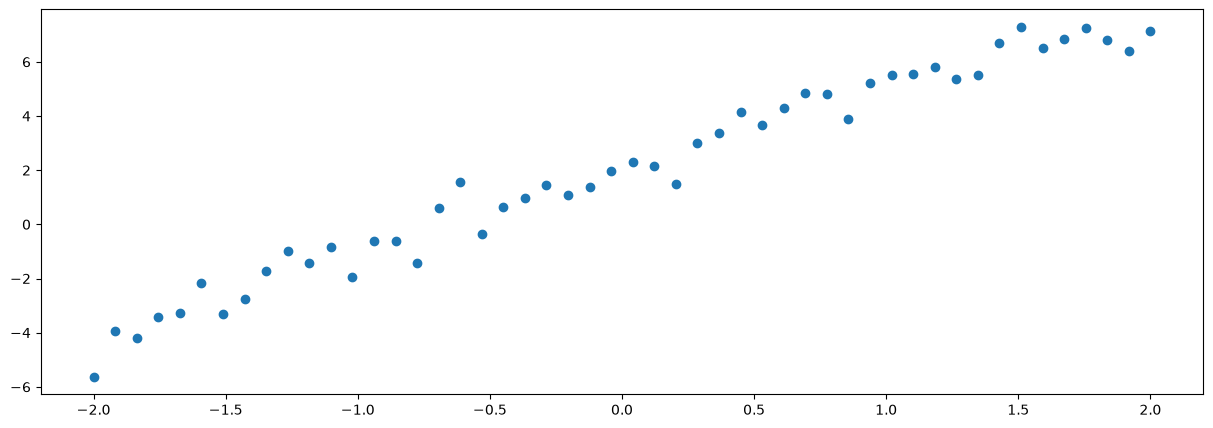

In [25]:
plt.figure(figsize=(15,5))
plt.scatter(x,y)

In [26]:
import torch.nn as nn

In [27]:
model = nn.Linear(1,1)

In [53]:
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.1)
epochs = 100 
losses =[]
for epoch in range(epochs):
    y_pred= model(x)
    loss = loss_function(y, y_pred)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 100 == 0 :
        print(f"Epoch : {epoch}/{epochs}, loss = {loss.item()}")


Epoch : 0/100, loss = 0.3774510324001312


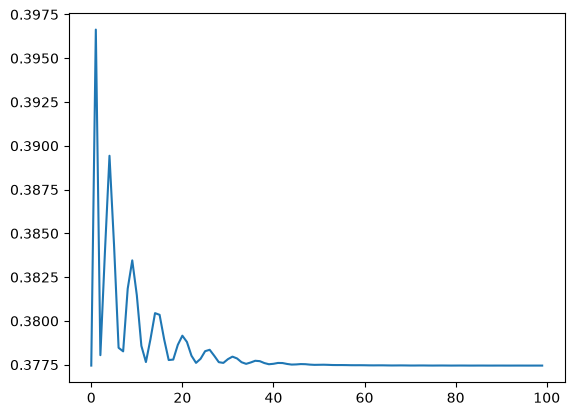

In [54]:
plt.plot(losses)

In [44]:
with torch.inference_mode():
    pred = model(x)

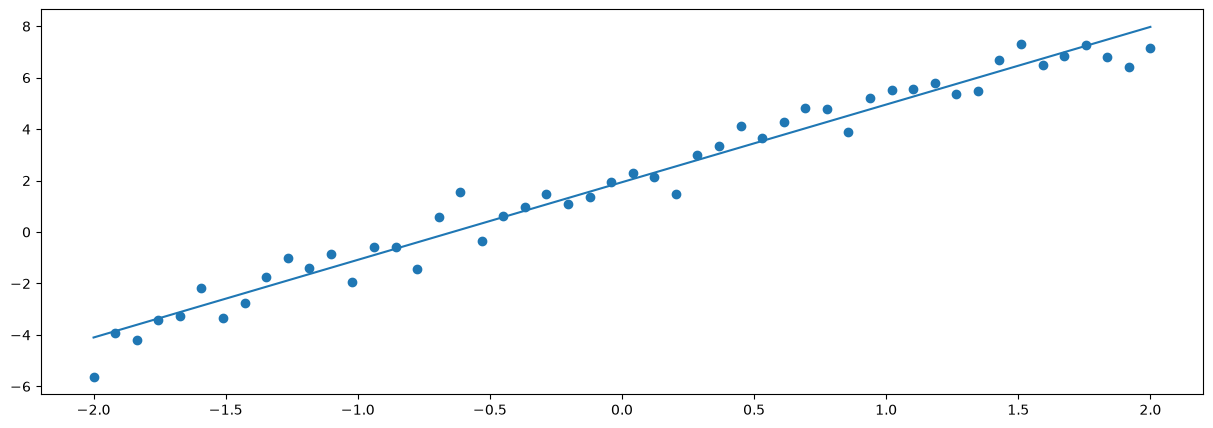

In [45]:
plt.figure(figsize=(15,5))
plt.scatter(x,y)
plt.plot(x,pred)

In [46]:
from torcheval.metrics import R2Score

In [47]:
r2_score = R2Score()
r2_score.update(y,pred)
score = r2_score.compute()

In [48]:
print(score)

tensor(0.9702)
